# Philippine Fuel Prices: KPIs and Segmentation (Milestone 5, Path B)

**Problem statement:** How have Philippine retail fuel prices changed over time, and how do they vary by region and fuel type?

The M4 notebook (`insights.ipynb`) answered the headline questions. This notebook goes one level deeper in two ways:

1. **KPI framework (Part 1):** five named KPIs, how each is calculated, and how they trend over time.
2. **Segmentation (Part 2):** four comparison views, each cutting the data by two dimensions (fuel x month, brand x fuel, brand x period, city x period) to see where the differences really are.

**How the numbers get here:** the heavy lifting is done by scripts, not by this notebook. `scripts/kpis.py` writes the KPI tables to `output/kpis/` and `scripts/segments.py` writes the segment tables to `output/segments/`. This notebook only reads those files and presents them, so the notebook and the pipeline cannot disagree. Regenerate them with `python scripts/run_pipeline.py --skip-ingest`.

**Audience:** consumers, journalists and researchers (plain-language takeaways under each chart), plus technical reviewers (method notes).

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Works whether the notebook is run from notebooks/ or from the repo root
ROOT = Path("..") if Path("../data").exists() else Path(".")
KPI_DIR = ROOT / "output" / "kpis"
SEG_DIR = ROOT / "output" / "segments"
FIG_DIR = ROOT / "output" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

# The notebook reads files produced by the pipeline; fail with a helpful message if they are missing.
needed = [KPI_DIR / "kpi_weekly_by_fuel.csv", KPI_DIR / "kpi_scorecard.csv", KPI_DIR / "kpi_brand_premium.csv",
          SEG_DIR / "segment_fuel_by_month.csv", SEG_DIR / "segment_brand_by_fuel.csv",
          SEG_DIR / "segment_brand_by_period.csv", SEG_DIR / "segment_city_by_period.csv"]
missing = [p.name for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run `python scripts/run_pipeline.py --skip-ingest` first.")

weekly = pd.read_csv(KPI_DIR / "kpi_weekly_by_fuel.csv", parse_dates=["week_start"])
scorecard = pd.read_csv(KPI_DIR / "kpi_scorecard.csv")
brand_kpi = pd.read_csv(KPI_DIR / "kpi_brand_premium.csv")
seg_month = pd.read_csv(SEG_DIR / "segment_fuel_by_month.csv")
seg_bf = pd.read_csv(SEG_DIR / "segment_brand_by_fuel.csv")
seg_bp = pd.read_csv(SEG_DIR / "segment_brand_by_period.csv")
seg_city = pd.read_csv(SEG_DIR / "segment_city_by_period.csv")

print(f"{weekly['week_start'].nunique()} bulletins, {weekly['week_start'].min():%b %d, %Y} to {weekly['week_start'].max():%b %d, %Y}")
print("Calm period = bulletins before Mar 10, 2026 (the Mar 10 bulletin is missing); shock period = Mar 17, 2026 onward.")

48 bulletins, Jul 08, 2025 to Aug 04, 2026
Calm period = bulletins before Mar 10, 2026 (the Mar 10 bulletin is missing); shock period = Mar 17, 2026 onward.


## Part 1: KPI framework

Five KPIs, each traced back to the problem statement. Full definitions with formulas live in [`docs/KPI_DEFINITIONS.md`](../docs/KPI_DEFINITIONS.md).

| # | KPI | Plain-language meaning | How it is calculated | Saved in |
|---|-----|------------------------|----------------------|----------|
| 1 | **NCR average price** (₱/L) | What a typical liter of each fuel costs in Metro Manila | Brand price midpoints are averaged into a city price, then the 9 long-running cities are averaged | `kpi_weekly_by_fuel.csv` |
| 2 | **% above baseline** | How far prices sit above the calm pre-shock level | Price / baseline - 1, where the baseline is the average of the 8 bulletins before the shock (Jan 13 to Mar 3, 2026) | `kpi_weekly_by_fuel.csv` |
| 3 | **Week-over-week % change** | How fast prices are moving | Price / previous bulletin - 1, **only** when bulletins are exactly 7 days apart | `kpi_weekly_by_fuel.csv` |
| 4 | **City premium** | Whether a city runs above or below the NCR market | City price / same-week, same-fuel average of all cities - 1, averaged over weeks | `kpi_city_premium.csv` |
| 5 | **Brand premium** | Whether a brand runs above or below the market | Brand price / same-city, same-week, same-fuel average of all brands - 1 (cells with 3+ brands), averaged over weeks | `kpi_brand_premium.csv` |

**KPI, not vanity metric.** The tempting alternative, "average price over the whole year", is a vanity metric here: the shock drags the mean far above the typical calm-period price (M4 showed diesel's mean at ₱71.6 against a median of ₱57.3), so it describes neither period. KPIs 2 and 3 are relative to a stated baseline and a stated gap length, and KPIs 4 and 5 compare like with like (same week, same fuel).

### KPI scorecard (from `output/kpis/kpi_scorecard.csv`)

In [2]:
scorecard

,product,baseline_price,latest_week,latest_price,latest_pct_vs_baseline,peak_week,peak_price,peak_pct_vs_baseline
0,Diesel,56.62,2026-08-04,90.85,60.4,2026-04-07,148.25,161.8
1,Diesel Plus,63.79,2026-08-04,96.20,50.8,2026-04-07,156.48,145.3
2,Kerosene,83.33,2026-08-04,120.57,44.7,2026-04-07,163.93,96.7
3,RON 91,56.23,2026-08-04,80.61,43.4,2026-04-07,96.02,70.8
4,RON 95,59.71,2026-08-04,83.55,39.9,2026-04-07,100.11,67.7
5,RON 100,66.36,2026-08-04,89.86,35.4,2026-04-07,106.29,60.2
6,RON 97,65.49,2026-08-04,89.06,36.0,2026-04-07,104.04,58.9


**Reading the scorecard.** Each row is one fuel. The baseline is its calm pre-shock price, the peak is its highest NCR average, and the latest value is the most recent bulletin. Every fuel peaked in the same bulletin (Apr 7, 2026) and is still above its baseline at the latest bulletin.

### KPI 2 over time: how far above baseline is each fuel?

Putting every fuel on the same "% above its own baseline" scale makes fuels with very different price levels directly comparable. The fuels split into two natural groups: diesel-family fuels and kerosene, and the four gasoline grades.

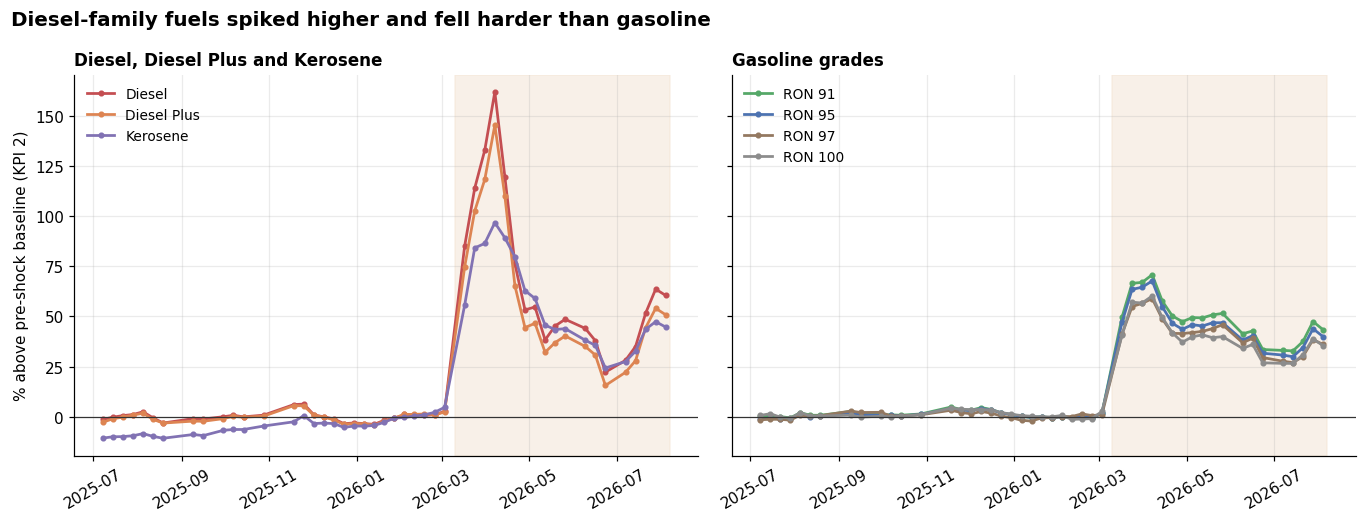

In [3]:
groups = {
    "Diesel, Diesel Plus and Kerosene": (["Diesel", "Diesel Plus", "Kerosene"], ["#c44e52", "#dd8452", "#8172b3"]),
    "Gasoline grades": (["RON 91", "RON 95", "RON 97", "RON 100"], ["#55a868", "#4c72b0", "#937860", "#8c8c8c"]),
}
shock_first = weekly.loc[weekly["period"] == "shock", "week_start"].min()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for ax, (title, (fuels, colors)) in zip(axes, groups.items()):
    for fuel, color in zip(fuels, colors):
        d = weekly[weekly["product"] == fuel]
        ax.plot(d["week_start"], d["pct_vs_baseline"], marker="o", ms=3, lw=1.8, color=color, label=fuel)
    ax.axhline(0, color="#333", lw=0.8)
    ax.axvspan(shock_first - pd.Timedelta(days=7), weekly["week_start"].max() + pd.Timedelta(days=3), color="#f3e3d3", alpha=0.5, zorder=0)
    ax.set_title(title, fontsize=11)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% above pre-shock baseline (KPI 2)")
fig.suptitle("Diesel-family fuels spiked higher and fell harder than gasoline", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_kpi_pct_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

### What it shows
Before March 2026 every fuel hovers around 0% (kerosene sits below zero early on because it was already drifting upward before the shock). At the peak, diesel was about 162% above baseline and Diesel Plus 145%, against 59-71% for the gasoline grades. Since June the two groups have behaved differently: diesel has climbed back from about +35% to +60% at the latest bulletin, while the gasoline grades have stayed between about +31% and +43%.

### So what
A single "fuel prices" number would hide this split. Reporting KPI 2 by fuel group tells readers which fuels are still far from normal (diesel, Diesel Plus, kerosene) and which are closer (gasoline grades).

## Part 2: Segmentation

Each view cuts the data by two dimensions. The plan:

| Segment dimensions | Why it matters | Comparison metric |
|--------------------|----------------|-------------------|
| Fuel x month (a time cohort) | Did every fuel get hit and recover in the same way? | Mean % above baseline (KPI 2) |
| Brand x fuel | Does a brand's price position depend on the fuel? | Brand premium % (KPI 5) |
| Brand x period (calm vs shock) | Did brand gaps scale up when prices rose by half? | Brand premium in % **and** in pesos |
| City x period (calm vs shock) | Do city differences persist, or were they a shock artifact? | City premium % (KPI 4) |

"Calm" and "shock" are defined by date only (before and after the March 2026 jump), so the split cannot tell us *why* anything changed.

### Segment A: fuel x month

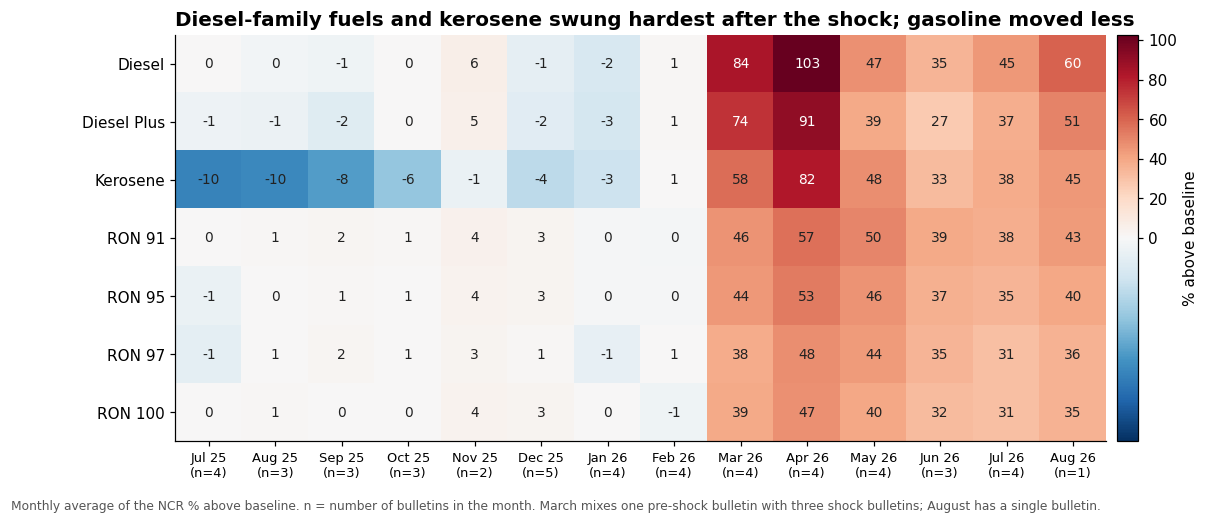

In [4]:
order = ["Diesel", "Diesel Plus", "Kerosene", "RON 91", "RON 95", "RON 97", "RON 100"]
heat = seg_month.pivot(index="product", columns="month", values="mean_pct_vs_baseline").loc[order]
bulletins = seg_month.groupby("month")["bulletins"].first()
labels = [f"{pd.Timestamp(m + '-01'):%b %y}\n(n={bulletins[m]})" for m in heat.columns]

fig, ax = plt.subplots(figsize=(13, 4.8))
norm = TwoSlopeNorm(vmin=-15, vcenter=0, vmax=float(np.nanmax(heat.values)))
im = ax.imshow(heat.values, cmap="RdBu_r", norm=norm, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        txt = f"{v:.0f}"
        ax.text(j, i, "0" if txt == "-0" else txt, ha="center", va="center", fontsize=9, color="white" if v > 60 else "#222")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.grid(False)
fig.colorbar(im, ax=ax, pad=0.01, label="% above baseline")
ax.set_title("Diesel-family fuels and kerosene swung hardest after the shock; gasoline moved less")
fig.text(0.01, -0.02, "Monthly average of the NCR % above baseline. n = number of bulletins in the month. March mixes one pre-shock "
         "bulletin with three shock bulletins; August has a single bulletin.", fontsize=8, color="#555")
fig.savefig(FIG_DIR / "07_segment_fuel_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

#### What it shows
Pre-shock months stay within about +/-6% for every fuel except kerosene, which was about 10% below its later baseline in mid-2025 because it was already creeping up. April 2026 is the peak month: diesel +103%, Diesel Plus +91% and kerosene +82%, versus +47% to +57% for gasoline grades. By June diesel had fallen to about the same level as gasoline (+35% against +32% to +39%), but it then rose again to +45% in July and +60% in August while gasoline stayed between +31% and +43%.

#### Careful conclusion
Diesel is the most volatile fuel in this data: highest at the peak, and the one that rebounded most. But August rests on a single bulletin, so the rebound should be treated as a signal to watch, not a settled trend. Kerosene's baseline already contains some of its pre-shock climb, which makes its "% above baseline" look smaller than it would against mid-2025.

### Segment B: brand x fuel

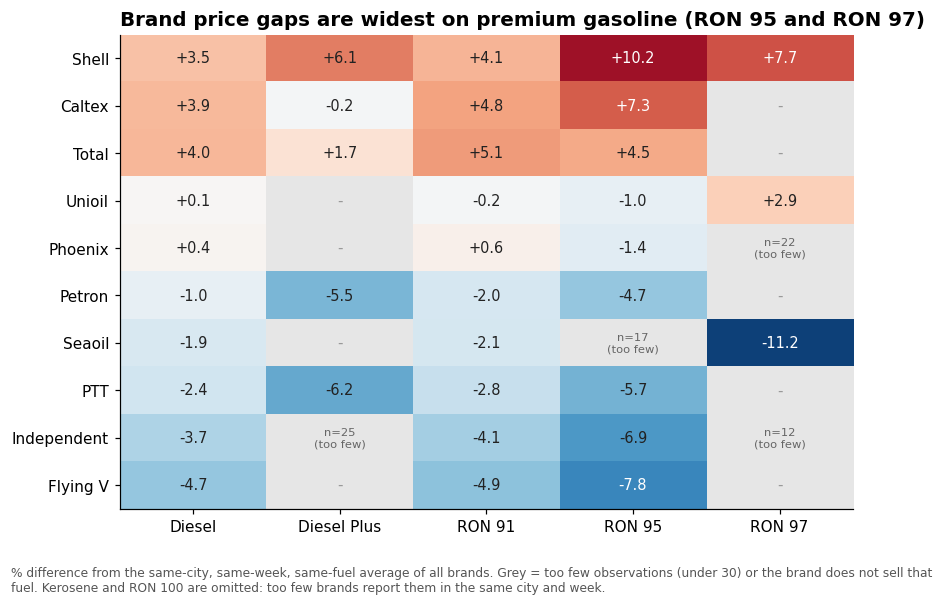

In [5]:
cols = ["Diesel", "Diesel Plus", "RON 91", "RON 95", "RON 97"]
brand_order = brand_kpi.sort_values("mean_premium_pct", ascending=False)["brand"].tolist()

shown = seg_bf.copy()
mat = shown.assign(v=np.where(shown["low_sample"], np.nan, shown["premium_pct"])).pivot(index="brand", columns="product", values="v").reindex(index=brand_order, columns=cols)
low = shown[shown["low_sample"]].pivot(index="brand", columns="product", values="n_rows").reindex(index=brand_order, columns=cols)

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#e6e6e6")
fig, ax = plt.subplots(figsize=(8.6, 5.6))
ax.imshow(np.ma.masked_invalid(mat.values), cmap=cmap, norm=TwoSlopeNorm(vmin=-12, vcenter=0, vmax=12), aspect="auto")
for i, b in enumerate(brand_order):
    for j, c in enumerate(cols):
        v = mat.loc[b, c]
        if pd.notna(v):
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9.5, color="white" if abs(v) > 7 else "#222")
        elif pd.notna(low.loc[b, c]):
            ax.text(j, i, f"n={int(low.loc[b, c])}\n(too few)", ha="center", va="center", fontsize=7.5, color="#666")
        else:
            ax.text(j, i, "-", ha="center", va="center", color="#999")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
ax.set_yticks(range(len(brand_order))); ax.set_yticklabels(brand_order)
ax.grid(False)
ax.set_title("Brand price gaps are widest on premium gasoline (RON 95 and RON 97)")
fig.text(0.01, -0.02, "% difference from the same-city, same-week, same-fuel average of all brands. Grey = too few observations "
         "(under 30) or the brand does not sell that fuel. Kerosene and RON 100 are omitted: too few brands report them in the same city and week.",
         fontsize=8, color="#555", wrap=True)
fig.savefig(FIG_DIR / "08_segment_brand_by_fuel.png", dpi=150, bbox_inches="tight")
plt.show()

#### What it shows
A brand's price position depends on the fuel. Shell sits +10.2% above the market on RON 95 but only +3.5% on diesel; Caltex is +7.3% on RON 95 against +3.9% on diesel; Flying V is -7.8% on RON 95 against -4.7% on diesel. The spread from the dearest to the cheapest brand is about 18 points on RON 95 and about 19 on RON 97 (where only three brands have enough data), against about 10 on RON 91 and 9 on diesel.

#### Careful conclusion
Brand choice seems to matter most for premium gasoline (RON 95 and RON 97). Two limits apply: the "market average" is made of whichever brands sell that fuel, so premiums compare better *within* a column than across columns, and four cells with fewer than 30 observations are greyed out rather than interpreted.

#### So what
Consumers who buy premium gasoline (RON 95 or RON 97) have the most to gain from comparing brands the same week; for diesel the gaps are smaller.

### Segment C: brand x period (calm vs shock)

When average prices rose by about half, did brand gaps grow with them? The same gap is shown two ways: as a percentage and in pesos per liter.

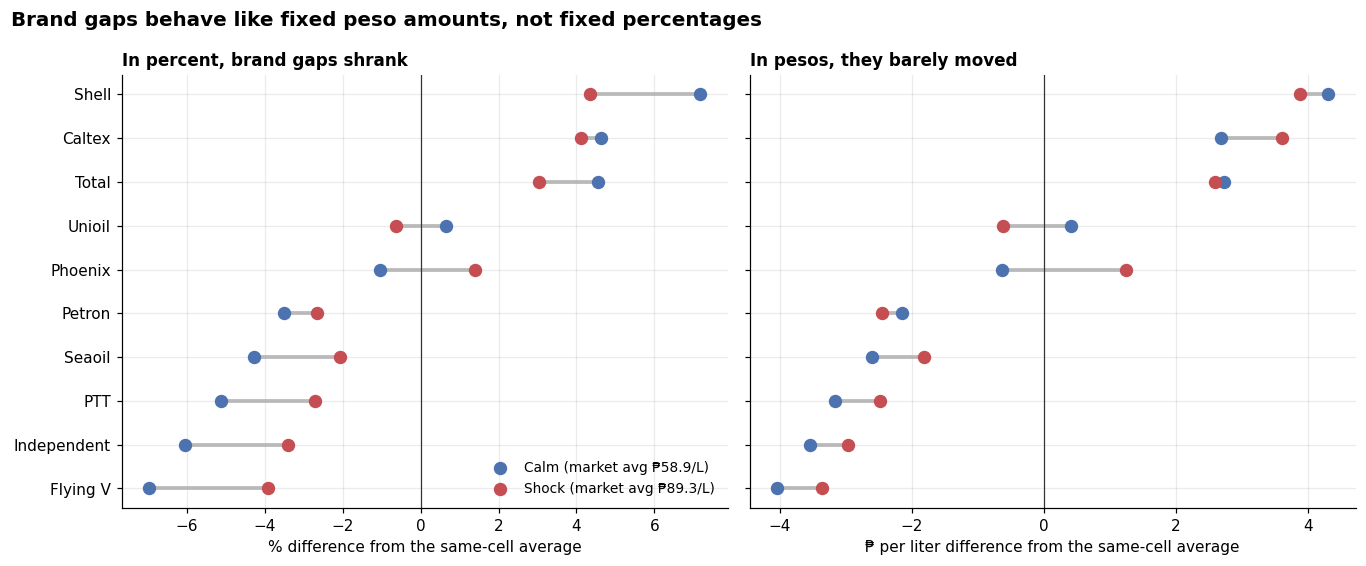

,pct calm,pct shock,php calm,php shock
brand,,,,
Shell,7.18,4.34,4.31,3.88
Caltex,4.63,4.12,2.68,3.62
Total,4.56,3.04,2.73,2.59
Unioil,0.65,-0.64,0.41,-0.62
Phoenix,-1.04,1.39,-0.63,1.25
Petron,-3.51,-2.67,-2.15,-2.45
Seaoil,-4.29,-2.07,-2.60,-1.82
PTT,-5.11,-2.72,-3.16,-2.48
Independent,-6.06,-3.41,-3.54,-2.98


In [6]:
pivot = seg_bp.pivot(index="brand", columns="period", values=["premium_pct", "premium_php"])
order_c = pivot[("premium_pct", "calm")].sort_values().index.tolist()
mkt = seg_bp.groupby("period")["avg_market_price"].first()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharey=True)
panels = [("premium_pct", "% difference from the same-cell average"), ("premium_php", "₱ per liter difference from the same-cell average")]
for ax, (key, xlabel) in zip(axes, panels):
    for i, brand in enumerate(order_c):
        a, b = pivot.loc[brand, (key, "calm")], pivot.loc[brand, (key, "shock")]
        ax.plot([a, b], [i, i], color="#bbb", lw=2.5, zorder=1)
        ax.scatter(a, i, s=60, color="#4c72b0", zorder=2, label=f"Calm (market avg ₱{mkt['calm']:.1f}/L)" if i == 0 else None)
        ax.scatter(b, i, s=60, color="#c44e52", zorder=2, label=f"Shock (market avg ₱{mkt['shock']:.1f}/L)" if i == 0 else None)
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_xlabel(xlabel)
axes[0].set_yticks(range(len(order_c))); axes[0].set_yticklabels(order_c)
axes[0].set_title("In percent, brand gaps shrank", fontsize=11)
axes[1].set_title("In pesos, they barely moved", fontsize=11)
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Brand gaps behave like fixed peso amounts, not fixed percentages", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_segment_brand_gap_pct_vs_php.png", dpi=150, bbox_inches="tight")
plt.show()

gaps = pivot.copy()
gaps.columns = [f"{k.replace('premium_', '')} {p}" for k, p in gaps.columns]
gaps.loc[order_c[::-1]].round(2)

#### What it shows
In percentage terms, brand gaps shrank during the shock: Shell went from +7.2% to +4.3%, Independent from -6.1% to -3.4%, Flying V from -7.0% to -3.9%. In pesos the same gaps hardly moved: Shell +₱4.31 to +₱3.88, Independent -₱3.54 to -₱2.98, Flying V -₱4.04 to -₱3.36, even though the average market price rose from about ₱59 to about ₱89 per liter.

#### Careful conclusion
In this data, brand price differences look more like roughly fixed peso amounts than fixed percentages: they did not scale up when prices rose by about half. A few brands moved more (Phoenix about +₱1.9, Unioil about -₱1.0), so this is a general pattern, not a rule. The data cannot say why: these are DOE-reported price ranges, not margins or costs.

#### So what
When prices are high, the *percentage* advantage of a cheaper brand looks smaller, but the *peso* saving per liter is about the same. Journalists and consumers should quote brand gaps in pesos.

### Segment D: city x period (calm vs shock)

Do city differences persist when prices jump, or were they a feature of the shock? Only the 9 long-running cities are used so both periods are comparable. A city on the dashed line would have the same premium in both periods.

Correlation of city premiums, calm vs shock (9 cities): Pearson 0.90, Spearman 0.73


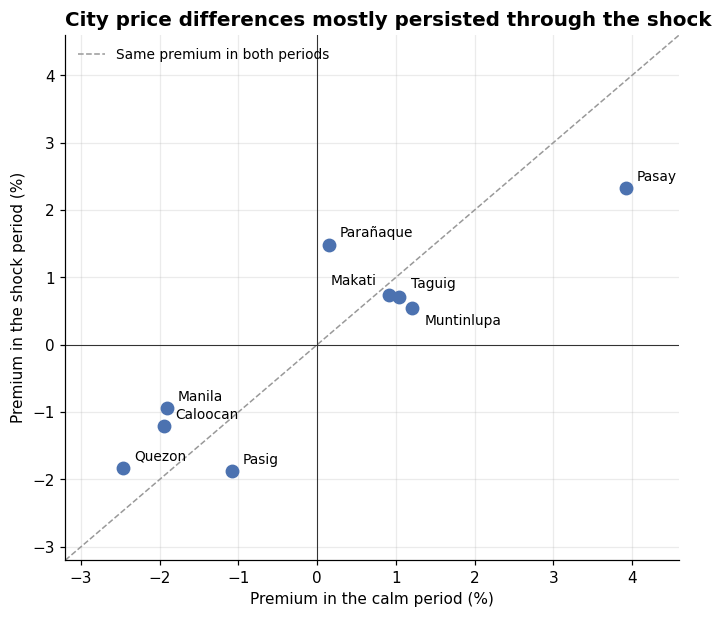

period,calm,shock
city,,
Quezon City,-2.46,-1.84
Caloocan City,-1.94,-1.21
Manila City,-1.90,-0.94
Pasig City,-1.09,-1.88
Parañaque City,0.15,1.48
Makati City,0.91,0.73
Taguig City,1.04,0.71
Muntinlupa City,1.21,0.55
Pasay City,3.92,2.33


In [7]:
cp = seg_city.pivot(index="city", columns="period", values="premium_pct")
r_pearson = cp["calm"].corr(cp["shock"])
r_spearman = cp["calm"].corr(cp["shock"], method="spearman")
print(f"Correlation of city premiums, calm vs shock (9 cities): Pearson {r_pearson:.2f}, Spearman {r_spearman:.2f}")

offsets = {"Makati City": (-8, 7, "right"), "Taguig City": (8, 6, "left"), "Muntinlupa City": (8, -11, "left")}
fig, ax = plt.subplots(figsize=(7.2, 6.2))
lo, hi = -3.2, 4.6
ax.plot([lo, hi], [lo, hi], ls="--", color="#999", lw=1, label="Same premium in both periods")
ax.axhline(0, color="#333", lw=0.7); ax.axvline(0, color="#333", lw=0.7)
ax.scatter(cp["calm"], cp["shock"], s=65, color="#4c72b0", zorder=3)
for city, row in cp.iterrows():
    dx, dy, ha = offsets.get(city, (7, 5, "left"))
    ax.annotate(city.replace(" City", ""), (row["calm"], row["shock"]), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("Premium in the calm period (%)")
ax.set_ylabel("Premium in the shock period (%)")
ax.set_title("City price differences mostly persisted through the shock")
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.savefig(FIG_DIR / "10_segment_city_calm_vs_shock.png", dpi=150, bbox_inches="tight")
plt.show()
cp.round(2).sort_values("calm")

#### What it shows
City premiums keep a similar pattern in both periods (correlation 0.90 on the premium values, 0.73 on the rankings, across the nine cities). Pasay is the highest in both (+3.9% calm, +2.3% shock); Quezon City, Caloocan, Manila and Pasig stay below the market in both (about -1% to -2.5%). Parañaque moved the most, from +0.2% to +1.5%.

#### Careful conclusion
City differences look persistent rather than a side effect of the shock, especially at the extremes (Pasay at the top; Quezon City, Caloocan, Manila and Pasig below average in both periods), while the middle of the ranking reshuffles a little. They are also small, roughly ₱1 to ₱3 per liter at typical prices, and a correlation across nine cities is a rough summary, not strong proof. As in the M4 notebook, no city-level explanation is possible without station-level data.

## What the segments can and cannot tell us

**What they support**
- Fuel type is the biggest dividing line: diesel-family fuels and kerosene moved much more than gasoline, and diesel is the one still diverging.
- Brand differences are larger than city differences, depend on the fuel (largest on premium gasoline), and are better described in pesos than in percent.
- City differences are small and stable.

**What they do not support**
- *Causes.* "Calm" and "shock" are separated by date only, so the shock is mixed up with anything else that changed over time. Nothing here explains why prices or gaps moved.
- *Precision.* Four brand x fuel cells have too few observations and are not interpreted; August 2026 is one bulletin; 9 weekly bulletins are missing (including Mar 10, 2026).
- *Coverage.* The data is NCR only, so "region" means NCR city. Regional bulletins would be needed for the nationwide question.
- *Individual pump prices.* Each value is the midpoint of a DOE-reported range for a brand in a city.

**Hand-off to Phase 6 (deployment).** A dashboard can read the saved tables directly, with no recomputation: `output/kpis/kpi_scorecard.csv` for the headline cards, `kpi_weekly_by_fuel.csv` for trend charts, and the files in `output/segments/` for the comparison views.